# 图 4–6：实验结果图

先修改下一单元的集中参数，再选择“重新启动内核并全部运行”。单幅图可在运行公共定义后分别重绘。代码只读取保存的实验 JSON。执行绘图单元即保存 PDF 和 PNG 到 `paper/figures`；调整完成后保存 notebook，再双击 `paper/build_pdf.cmd` 编译。

全局字号：`FONT_SCALE`；逐项字号：`FONT_*`；布局：`*_LAYOUT`；密集标签：`SEED_LABEL_OFFSETS`。所有字号以 160 mm 插图宽度为基准。


In [1]:
# ===== 所有常用参数集中在这里；修改后“全部运行” =====
FONT_SCALE = 1.0
FONT_FAMILY = ["Times New Roman", "SimSun"]  # 英文与数字 / 中文
FONT_TITLE = 11
FONT_LABEL = 10
FONT_TICK = 9
FONT_LEGEND = 9
FONT_ANNOTATION = 9
FONT_PANEL = 11
FIGURE_WIDTH_MM = 160
FIGURE_HEIGHT_MM = {"known": 163, "reconstruction": 158, "calibration": 160}
LINE_WIDTH = 1.4
TRUTH_LINE_WIDTH = 1.9
MARKER_SIZE = 3.5
GRID_ALPHA = 0.22
BAR_WIDTH_MODELS = 0.15
BAR_WIDTH_NETWORKS = 0.24
BAR_WIDTH_COMPARE = 0.33
DPI_PREVIEW = 150
DPI_EXPORT = 300
PANEL_POSITION = (-0.18, 1.13)
RECON_PANEL_POSITION = (-0.085, 1.13)
NETWORK_LEGEND_LOCATION = 'upper right'
TRAJECTORY_LEGEND_LOCATION = 'upper right'
SEED_LEADER_WIDTH = 0.6
RECON_Y_LIMITS = (-0.02, 1.25)
VALUE_LABEL_ROTATION = 90
KNOWN_LAYOUT = {"left": 0.13, "right": 0.99, "bottom": 0.10, "top": 0.83, "hspace": 0.60, "wspace": 0.48}
CALIBRATION_LAYOUT = {"left": 0.13, "right": 0.99, "bottom": 0.09, "top": 0.86, "hspace": 0.55, "wspace": 0.50}
RECON_LAYOUT = {"left": 0.12, "right": 0.95, "bottom": 0.14, "top": 0.90, "hspace": 0.48, "wspace": 0.38}
RECON_HEIGHT_RATIOS = [1.0, 1.05]
KNOWN_LEGEND_ANCHOR = (0.53, 1.0)
CALIBRATION_LEGEND_ANCHOR = (0.52, 1.0)
RECON_LEGEND_ANCHOR = (0.53, 0.025)
LEGEND_COLUMNS = {"known": 3, "calibration": 2, "edges": 3}
VALUE_LABEL_OFFSET = 0.00035
SEED_MARKER_AREA = 46
SELECTED_MARKER_AREA = 130
# 密集区域可逐个调整；单位为 points，(横向偏移, 纵向偏移)
SEED_LABEL_OFFSETS = {
    ("ER", 7): (4, 6), ("ER", 21): (12, -19), ("ER", 42): (-13, 9),
    ("WS", 7): (-9, -33), ("WS", 21): (4, 6), ("WS", 42): (-16, 14),
    ("BA", 7): (10, 15), ("BA", 21): (-20, 6), ("BA", 42): (16, -15),
}
NETS = ["ER", "WS", "BA"]
NET_NAMES = {"ER": "ER 随机网络", "WS": "WS 小世界网络", "BA": "BA 无标度网络"}
NET_COLORS = {"ER": "#2F6B9A", "WS": "#E07A3F", "BA": "#3D8B5A"}
MODEL_KEYS = ["gcn1l_dir", "gcn1l_bi", "gcn3l_bi", "gcn3l_bi_mean", "twob3l_bi"]
MODEL_SHORT = {
    "gcn1l_dir": "单向\n求和-1L", "gcn1l_bi": "双向\n求和-1L",
    "gcn3l_bi": "双向\n求和-3L", "gcn3l_bi_mean": "双向\n均值-3L",
    "twob3l_bi": "双向\n双通道",
}
MODEL_TICK_LABELS = {k: v.replace('-', '\n') for k, v in MODEL_SHORT.items()}
MODEL_COLORS = ["#8C8C8C", "#E6863B", "#2B6CB0", "#4A8F55", "#C43C39"]
COMPARE_COLORS = ["#4878A8", "#D97642"]
EDGE_COLORS = {0: [1, 1, 1], 1: [0.12, 0.12, 0.12], 2: [0.84, 0.20, 0.18], 3: [0.16, 0.38, 0.75]}


In [2]:
from pathlib import Path
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

def find_root():
    for p in (Path.cwd(), *Path.cwd().parents):
        if (p / "paper" / "main.tex").is_file():
            return p
    raise FileNotFoundError("请从项目目录或 paper/notebooks 内启动 notebook。")

ROOT = find_root()
PAPER = ROOT / "paper"
FIG_DIR = PAPER / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

from matplotlib.patches import Patch
from matplotlib.lines import Line2D
P4_PATH = ROOT / 'two_channel_experiment/results/phase4/phase4_five_models.json'
P6_DIR = ROOT / 'two_channel_experiment/results/phase6'


In [3]:
def setup_style() -> None:
    plt.rcParams.update(
        {
            "font.family": FONT_FAMILY,
            "font.serif": ["SimSun", "Times New Roman"],
            "font.sans-serif": ["SimSun", "Microsoft YaHei", "SimHei"],
            "mathtext.fontset": "stix",
            "axes.unicode_minus": False,
            "axes.titlesize": FONT_TITLE * FONT_SCALE,
            "axes.labelsize": FONT_LABEL * FONT_SCALE,
            "xtick.labelsize": FONT_TICK * FONT_SCALE,
            "ytick.labelsize": FONT_TICK * FONT_SCALE,
            "legend.fontsize": FONT_LEGEND * FONT_SCALE,
            "figure.dpi": DPI_PREVIEW,
            "savefig.dpi": DPI_EXPORT,
            "pdf.fonttype": 42,
            "ps.fonttype": 42,
        }
    )


def load_json(path: Path) -> dict:
    with path.open(encoding="utf-8") as f:
        return json.load(f)


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def save_figure(fig: plt.Figure, name: str) -> None:
    # Matplotlib 的混合公式行不执行普通字体回退；为含中文的公式行指定宋体，公式仍由 STIX 排版。
    from matplotlib.text import Text
    for text in fig.findobj(match=Text):
        label = text.get_text()
        if '$' in label and any('\u4e00' <= c <= '\u9fff' for c in label):
            text.set_fontfamily(FONT_FAMILY[-1])
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / f"{name}.pdf", facecolor="white")
    fig.savefig(FIG_DIR / f"{name}.png", facecolor="white", dpi=DPI_EXPORT)
    display(fig)
    plt.close(fig)
    print(f"已导出：{(FIG_DIR / name).relative_to(ROOT).as_posix()}.pdf / .png")


def panel_label(ax: plt.Axes, label: str, position=PANEL_POSITION) -> None:
    ax.text(*position, label, transform=ax.transAxes, fontsize=FONT_PANEL * FONT_SCALE, fontweight="bold", va="top")


def known_topology_figure(p4: dict) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(FIGURE_WIDTH_MM / 25.4, FIGURE_HEIGHT_MM["known"] / 25.4))
    ba = p4["BA"]["models"]

    ax = axes[0, 0]
    truth = ba["twob3l_bi"]["perk"]
    ax.plot(truth["k"], truth["truth"], color="black", lw=TRUTH_LINE_WIDTH, label=r"真实曲线 $\beta=0.3$")
    for key, color in zip(MODEL_KEYS, MODEL_COLORS):
        perk = ba[key]["perk"]
        ax.plot(perk["k"], perk["pred"], marker="o", ms=MARKER_SIZE, lw=LINE_WIDTH, color=color, label=MODEL_SHORT[key].replace("\n", " "))
    ax.set_xlabel("感染者邻居数 $k$")
    ax.set_ylabel(r"预测感染概率 $P(S\to I\mid k)$")
    ax.set_title("BA 感染概率校准")
    ax.set_ylim(0, 1.04)
    ax.grid(alpha=GRID_ALPHA)
    panel_label(ax, "(a)")

    ax = axes[0, 1]
    labels = p4["BA"]["bucket_labels"]
    x = np.arange(len(labels))
    width = BAR_WIDTH_MODELS
    for idx, (key, color) in enumerate(zip(MODEL_KEYS, MODEL_COLORS)):
        vals = [ba[key]["beta_by_bucket"].get(label, np.nan) for label in labels]
        ax.bar(x + (idx - 2) * width, vals, width, color=color, label=MODEL_SHORT[key].replace("\n", " "))
    ax.axhline(0.3, color="black", ls="--", lw=LINE_WIDTH, label="真实值 0.3")
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel("节点度数分桶")
    ax.set_ylabel(r"反演感染率 $\hat{\beta}$")
    ax.set_title("BA 跨度数稳定性")
    ax.set_ylim(0, 0.49)
    ax.grid(axis="y", alpha=GRID_ALPHA)
    panel_label(ax, "(b)")

    ax = axes[1, 0]
    x = np.arange(len(MODEL_KEYS))
    width = BAR_WIDTH_NETWORKS
    for idx, net in enumerate(NETS):
        vals = [p4[net]["models"][key]["perk_mae"] for key in MODEL_KEYS]
        ax.bar(x + (idx - 1) * width, vals, width, label=NET_NAMES[net], color=NET_COLORS[net])
    ax.set_xticks(x)
    ax.set_xticklabels([MODEL_TICK_LABELS[key] for key in MODEL_KEYS])
    ax.set_ylabel("感染概率 MAE")
    ax.set_title("感染概率校准误差")
    ax.grid(axis="y", alpha=GRID_ALPHA)
    panel_label(ax, "(c)")

    ax = axes[1, 1]
    for idx, net in enumerate(NETS):
        vals = [p4[net]["models"][key]["autoreg"]["mae_i_mean"] for key in MODEL_KEYS]
        ax.bar(x + (idx - 1) * width, vals, width, label=NET_NAMES[net], color=NET_COLORS[net])
    ax.set_xticks(x)
    ax.set_xticklabels([MODEL_TICK_LABELS[key] for key in MODEL_KEYS])
    ax.set_ylabel("感染者占比 MAE")
    ax.set_title("自回归预测误差")
    ax.legend(NETS, frameon=False, loc=NETWORK_LEGEND_LOCATION)
    ax.grid(axis="y", alpha=GRID_ALPHA)
    panel_label(ax, "(d)")

    handles, labels_legend = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels_legend, loc="upper center", ncol=LEGEND_COLUMNS["known"], frameon=False, bbox_to_anchor=KNOWN_LEGEND_ANCHOR)
    fig.subplots_adjust(**KNOWN_LAYOUT)
    save_figure(fig, "known_topology_results")


def f1_from_hard(h: dict) -> tuple[float, float]:
    precision = h["tp"] / (h["tp"] + h["fp"]) if h["tp"] + h["fp"] else 0.0
    recall = h["tp"] / (h["tp"] + h["fn"]) if h["tp"] + h["fn"] else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return precision, f1


def reconstruction_figure(p6: dict, seed_runs: dict[tuple[str, int], dict]) -> None:
    fig = plt.figure(figsize=(FIGURE_WIDTH_MM / 25.4, FIGURE_HEIGHT_MM["reconstruction"] / 25.4))
    gs = fig.add_gridspec(2, 3, height_ratios=RECON_HEIGHT_RATIOS)
    ax = fig.add_subplot(gs[0, :])
    markers = {"ER": "o", "WS": "s", "BA": "^"}
    for net in NETS:
        xs, ys = [], []
        for seed in (7, 21, 42):
            run = seed_runs[(net, seed)]
            _, f1 = f1_from_hard(run["recon_hard_05"])
            xs.append(run["losses"]["best_val"])
            ys.append(f1)
            ax.annotate(str(seed), (xs[-1], ys[-1]), xytext=SEED_LABEL_OFFSETS[(net, seed)], textcoords="offset points", fontsize=FONT_ANNOTATION * FONT_SCALE, arrowprops=dict(arrowstyle='-', lw=SEED_LEADER_WIDTH, color=NET_COLORS[net]))
        ax.scatter(xs, ys, s=SEED_MARKER_AREA, marker=markers[net], color=NET_COLORS[net], label=NET_NAMES[net], edgecolor="white", linewidth=0.7)
        selected_seed = p6[net]["config"]["seed_selected"]
        selected = seed_runs[(net, selected_seed)]
        _, selected_f1 = f1_from_hard(selected["recon_hard_05"])
        ax.scatter([selected["losses"]["best_val"]], [selected_f1], s=SELECTED_MARKER_AREA, facecolors="none", edgecolors=NET_COLORS[net], linewidth=2.0)
    ax.set_xlabel("最低验证交叉熵")
    ax.set_ylabel("硬图 F1")
    ax.set_title("验证损失与结构重构质量")
    ax.set_ylim(*RECON_Y_LIMITS)
    ax.grid(alpha=GRID_ALPHA)
    ax.legend(frameon=False, ncol=1, loc="lower left")
    panel_label(ax, "(a)", RECON_PANEL_POSITION)

    color_map = {k: np.asarray(v) for k, v in EDGE_COLORS.items()}
    for idx, net in enumerate(NETS):
        ax = fig.add_subplot(gs[1, idx])
        true_a = np.asarray(p6[net]["matrices"]["true_adj"], dtype=int)
        hard_a = np.asarray(p6[net]["matrices"]["hard_adj"], dtype=int)
        cls = np.zeros_like(true_a, dtype=int)
        cls[(true_a == 1) & (hard_a == 1)] = 1
        cls[(true_a == 0) & (hard_a == 1)] = 2
        cls[(true_a == 1) & (hard_a == 0)] = 3
        rgb = np.zeros((*cls.shape, 3))
        for value, color in color_map.items():
            rgb[cls == value] = color
        ax.imshow(rgb, interpolation="nearest", origin="upper")
        h = p6[net]["recon_hard_05"]
        _, f1 = f1_from_hard(h)
        ax.set_title(f"{net}\nF1={f1:.3f}\n边数 {h['n_edges_pred']}/{h['n_edges_true']}", fontsize=FONT_ANNOTATION * FONT_SCALE)
        ax.set_xticks([0, 50, 99])
        ax.set_yticks([0, 50, 99])
        ax.set_xlabel("节点编号")
        if idx == 0:
            ax.set_ylabel("节点编号")
        panel_label(ax, f"({chr(ord('b') + idx)})")
    legend = [
        Patch(facecolor=color_map[1], label="正确边 TP"),
        Patch(facecolor=color_map[2], label="增边 FP"),
        Patch(facecolor=color_map[3], label="漏边 FN"),
    ]
    fig.legend(handles=legend, loc="lower center", ncol=LEGEND_COLUMNS["edges"], frameon=False, bbox_to_anchor=RECON_LEGEND_ANCHOR)
    fig.subplots_adjust(**RECON_LAYOUT)
    save_figure(fig, "seed_selection_and_reconstruction")


def calibration_autoreg_figure(p4: dict, p6: dict) -> None:
    fig, axes = plt.subplots(2, 2, figsize=(FIGURE_WIDTH_MM / 25.4, FIGURE_HEIGHT_MM["calibration"] / 25.4))

    ax = axes[0, 0]
    k = np.arange(1, 11)
    ax.plot(k, 1 - (1 - 0.3) ** k, color="black", lw=TRUTH_LINE_WIDTH, label=r"真实曲线 $\beta=0.3$")
    for net in NETS:
        perk = p6[net]["eval_extended"]["beta"]["perk"]
        ax.plot(perk["k"], perk["pred"], marker="o", ms=MARKER_SIZE, lw=LINE_WIDTH, color=NET_COLORS[net], label=NET_NAMES[net])
    ax.set_xlabel("感染者邻居数 $k$")
    ax.set_ylabel(r"预测感染概率 $P(S\to I\mid k)$")
    ax.set_title("未知拓扑下的机制校准")
    ax.set_ylim(0, 1.04)
    ax.grid(alpha=GRID_ALPHA)
    panel_label(ax, "(a)")

    ax = axes[0, 1]
    x = np.arange(len(NETS))
    width = BAR_WIDTH_COMPARE
    known_beta = [abs(p4[n]["models"]["twob3l_bi"]["beta_fit"][0] - 0.3) for n in NETS]
    unknown_beta = [abs(p6[n]["eval_extended"]["beta"]["fit"][0] - 0.3) for n in NETS]
    ax.bar(x - width / 2, known_beta, width, label="已知拓扑", color=COMPARE_COLORS[0])
    ax.bar(x + width / 2, unknown_beta, width, label="未知拓扑", color=COMPARE_COLORS[1])
    ax.set_xticks(x)
    ax.set_xticklabels(NETS)
    ax.set_ylabel(r"感染率绝对误差 $|\hat{\beta}-0.3|$")
    ax.set_title("感染率反演误差")
    ax.set_ylim(0, max(known_beta + unknown_beta) * 1.6)
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=GRID_ALPHA)
    panel_label(ax, "(b)")

    ax = axes[1, 0]
    known_mae = [p4[n]["models"]["twob3l_bi"]["autoreg"]["mae_i_mean"] for n in NETS]
    unknown_mae = [p6[n]["eval_extended"]["autoreg_5x5"]["mae_i_mean"] for n in NETS]
    ax.bar(x - width / 2, known_mae, width, label="已知拓扑", color=COMPARE_COLORS[0])
    ax.bar(x + width / 2, unknown_mae, width, label="未知拓扑", color=COMPARE_COLORS[1])
    for i, value in enumerate(known_mae):
        ax.text(i - width / 2, value + VALUE_LABEL_OFFSET, f"{value:.4f}", ha="center", rotation=VALUE_LABEL_ROTATION, fontsize=FONT_ANNOTATION * FONT_SCALE)
    for i, value in enumerate(unknown_mae):
        ax.text(i + width / 2, value + VALUE_LABEL_OFFSET, f"{value:.4f}", ha="center", rotation=VALUE_LABEL_ROTATION, fontsize=FONT_ANNOTATION * FONT_SCALE)
    ax.set_xticks(x)
    ax.set_xticklabels(NETS)
    ax.set_ylabel("感染者占比 MAE")
    ax.set_title("5×5 自回归推演误差")
    ax.set_ylim(0, max(known_mae + unknown_mae) * 1.5)
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=GRID_ALPHA)
    panel_label(ax, "(c)")

    ax = axes[1, 1]
    for net in NETS:
        tests = [t for t in p6[net]["eval_extended"]["autoreg_5x5"]["tests"] if t["n_inf"] == 3]
        true_curves = np.asarray([t["true"] for t in tests], dtype=float)
        pred_curves = np.asarray([t["pred"] for t in tests], dtype=float)
        true_mean = true_curves[:, :, 1].mean(axis=0)
        pred_mean = pred_curves[:, :, 1].mean(axis=0)
        tt = np.arange(len(true_mean))
        ax.plot(tt, true_mean, color=NET_COLORS[net], lw=TRUTH_LINE_WIDTH, label=f"{net} 真实")
        ax.plot(tt, pred_mean, color=NET_COLORS[net], lw=LINE_WIDTH, ls="--", label=f"{net} 预测")
    ax.set_xlabel("时间步")
    ax.set_ylabel("感染者占比")
    ax.set_title("平均感染轨迹")
    ax.legend(handles=[Line2D([], [], color='black', lw=TRUTH_LINE_WIDTH, label='真实'), Line2D([], [], color='black', lw=LINE_WIDTH, ls='--', label='预测')], frameon=False, loc=TRAJECTORY_LEGEND_LOCATION)
    ax.grid(alpha=GRID_ALPHA)
    panel_label(ax, "(d)")

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=LEGEND_COLUMNS["calibration"], frameon=False, bbox_to_anchor=CALIBRATION_LEGEND_ANCHOR)
    fig.subplots_adjust(**CALIBRATION_LAYOUT)
    save_figure(fig, "calibration_and_autoregression")


def build_manifest(p4: dict, p6: dict, seed_runs: dict[tuple[str, int], dict]) -> dict:
    models = {}
    labels = p4["config"]["model_labels"]
    for key in MODEL_KEYS:
        rows = []
        for net in NETS:
            x = p4[net]["models"][key]
            rows.append(
                {
                    "network": net,
                    "beta_hat": x["beta_fit"][0],
                    "per_k_mae": x["perk_mae"],
                    "gamma_hat": x["gamma"]["mean"],
                    "delta_gamma": x["delta_gamma"],
                    "autoreg_mae_i": x["autoreg"]["mae_i_mean"],
                }
            )
        models[key] = {
            "label": labels[key],
            "rows": rows,
            "mean_abs_beta_error": float(np.mean([abs(r["beta_hat"] - 0.3) for r in rows])),
            "mean_per_k_mae": float(np.mean([r["per_k_mae"] for r in rows])),
            "mean_abs_gamma_error": float(np.mean([abs(r["gamma_hat"] - 0.1) for r in rows])),
            "mean_delta_gamma": float(np.mean([r["delta_gamma"] for r in rows])),
            "mean_autoreg_mae_i": float(np.mean([r["autoreg_mae_i"] for r in rows])),
        }

    selected = {}
    all_runs = []
    for net in NETS:
        d = p6[net]
        h = d["recon_hard_05"]
        precision, f1 = f1_from_hard(h)
        selected[net] = {
            "seed": d["config"]["seed_selected"],
            "validation_ce": d["losses"]["best_val"],
            "auc_soft": d["recon"]["auc_soft"],
            "acc": h["acc"],
            "precision": precision,
            "f1": f1,
            "tpr": h["tpr"],
            "fpr": h["fpr"],
            "predicted_edges": h["n_edges_pred"],
            "true_edges": h["n_edges_true"],
            "beta_hat": d["eval_extended"]["beta"]["fit"][0],
            "per_k_mae": d["eval_extended"]["beta"]["perk_mae"],
            "gamma_hat": d["eval_extended"]["gamma"]["mean"],
            "gamma_output_std": d["eval_extended"]["gamma"]["std"],
            "delta_gamma": d["eval_extended"]["gamma"]["delta_gamma"],
            "autoreg_mae_i": d["eval_extended"]["autoreg_5x5"]["mae_i_mean"],
            "autoreg_mae_all": d["eval_extended"]["autoreg_5x5"]["mae_all_mean"],
        }
        for seed in (7, 21, 42):
            run = seed_runs[(net, seed)]
            h_run = run["recon_hard_05"]
            precision_run, f1_run = f1_from_hard(h_run)
            all_runs.append(
                {
                    "network": net,
                    "seed": seed,
                    "validation_ce": run["losses"]["best_val"],
                    "acc": h_run["acc"],
                    "precision": precision_run,
                    "f1": f1_run,
                    "tpr": h_run["tpr"],
                    "fpr": h_run["fpr"],
                    "predicted_edges": h_run["n_edges_pred"],
                    "true_edges": h_run["n_edges_true"],
                    "selected": seed == d["config"]["seed_selected"],
                }
            )

    source_paths = [P4_PATH] + [P6_DIR / f"dgsl_l1b_{n}.json" for n in NETS]
    source_paths += [P6_DIR / f"dgsl_l1b_{n}_s{s}.json" for n in NETS for s in (7, 21, 42)]
    return {
        "scope": "固定的三个 N=100 合成网络实例；phase4 与 phase6 保存结果；不重新训练",
        "sources": [
            {"path": str(p.relative_to(ROOT)).replace("\\", "/"), "sha256": sha256(p)} for p in source_paths
        ],
        "known_topology": models,
        "unknown_topology_selected": selected,
        "unknown_topology_all_runs": all_runs,
    }



In [4]:
setup_style()
p4 = load_json(P4_PATH)
p6 = {net: load_json(P6_DIR / f"dgsl_l1b_{net}.json") for net in NETS}
seed_runs = {(net, seed): load_json(P6_DIR / f"dgsl_l1b_{net}_s{seed}.json")
             for net in NETS for seed in (7, 21, 42)}
manifest = build_manifest(p4, p6, seed_runs)
(PAPER / "metrics_manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")


12942

## 图 4
运行下方单元预览并导出。

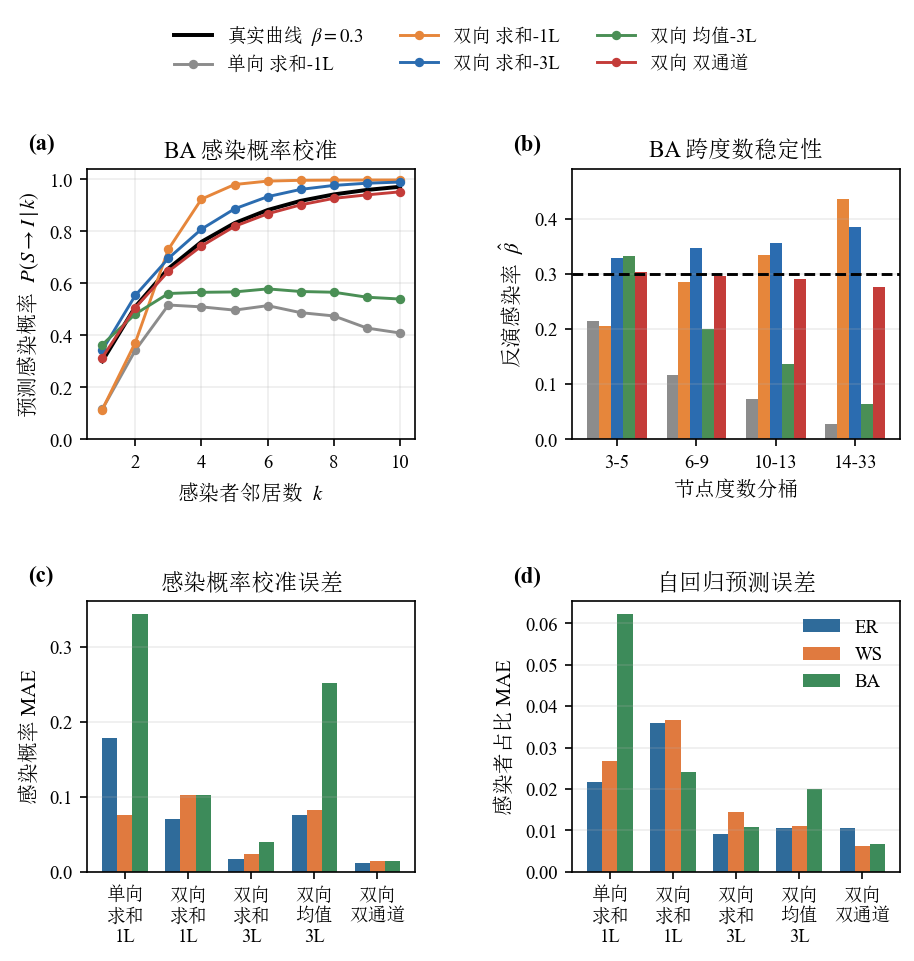

已导出：paper/figures/known_topology_results.pdf / .png


In [5]:
known_topology_figure(p4)

## 图 5
运行下方单元预览并导出。

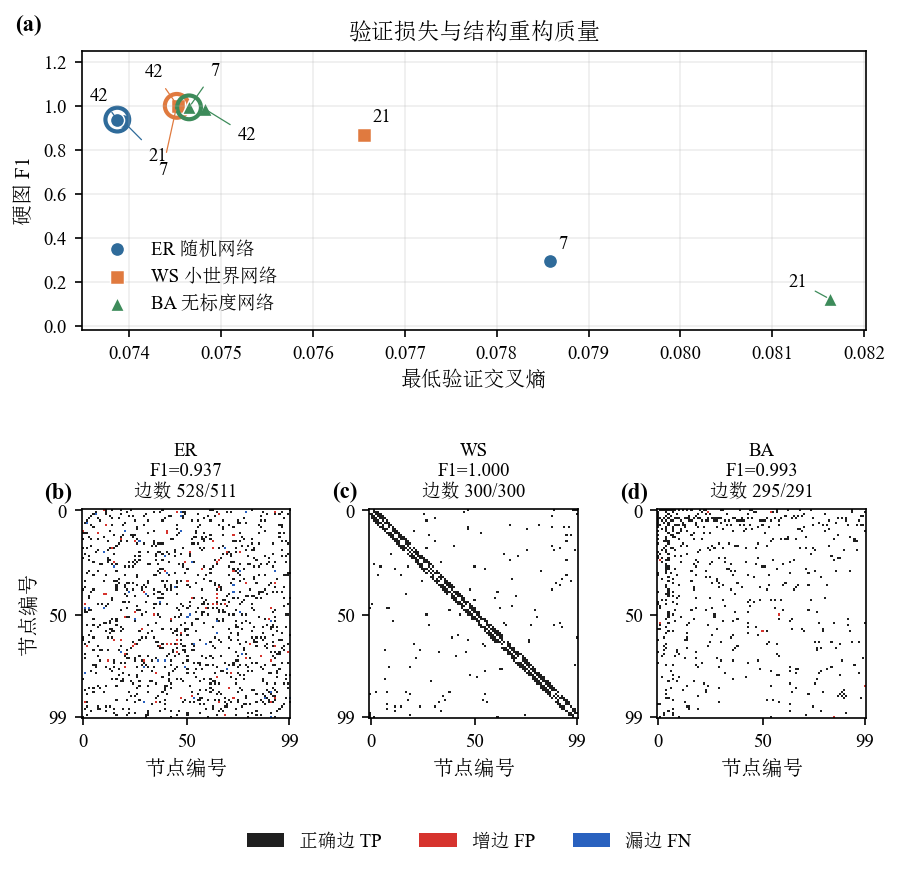

已导出：paper/figures/seed_selection_and_reconstruction.pdf / .png


In [6]:
reconstruction_figure(p6, seed_runs)

## 图 6
运行下方单元预览并导出。

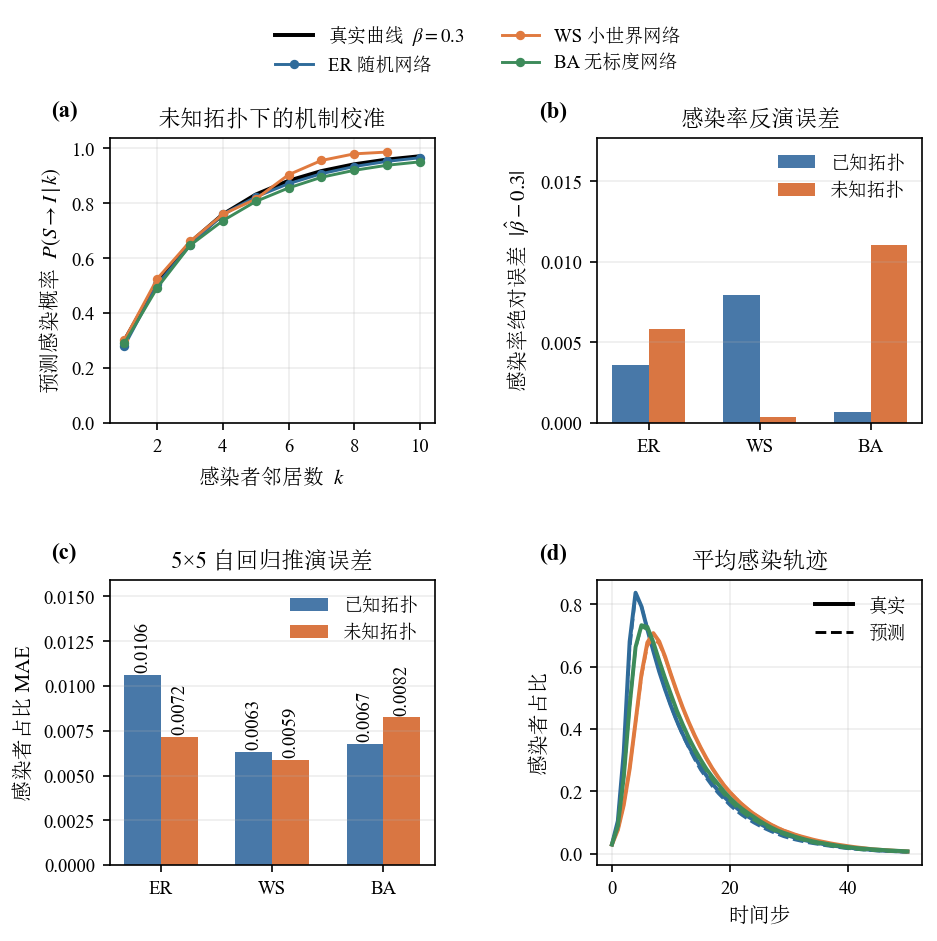

已导出：paper/figures/calibration_and_autoregression.pdf / .png


In [7]:
calibration_autoreg_figure(p4, p6)

## 调参示例
将 `FONT_SCALE` 改成 `1.1` 后全部运行，即可同时放大标题、标签、图例与数字。若产生拥挤，先调高画布高度或 `hspace`，再调整图例位置。修改参数单元后须重新运行该单元与 `setup_style()`，已有图不会自动刷新。